# 09 — Monitoring

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

The monitoring plan: what is tracked per period (score PSI with its chi-square critical value, CSI per attribute, the 12-month early indicator and 24-month performance where observable, calibration slope and intercept), the thresholds, and the decision rule that maps what moved to recalibrate / re-estimate / redevelop. The 2017Q1–2018Q4 vintages are the live monitor range; three simulated drifts show the rule reacting.

Decisions: **T — thresholds and cadence**, **U — the action per scenario**, **V — the monitoring plan text**.

In [4]:
frame = load_frame(include_indeterminate=True)
mon = A.build_attributes(target.modeling_frame(con, splits=("monitor",), include_indeterminate=True, sample_frac=SAMPLE_FRAC))
early = con.sql("SELECT id, early_bad, early_observable FROM v_split").df()
frame = frame.merge(early, on="id", how="left"); mon = mon.merge(early, on="id", how="left")
card, specs = S.load_card(MODELS / "champion")
for d in (frame, mon):
    sc = S.score(d, card, specs); d["score"] = sc["score"].values; d["eta"] = sc["eta"].values

# The deployed card: the intercept recalibrated on 2015 by prior correction (as in NB08), the version in use from the
# start of 2016. Its offset from the card as developed is reported once here, as the development-to-deployment shift.
tr0, va0 = (frame[(frame.split == s) & frame.bad.notna()] for s in ("train", "validate"))
CARD_SHIFT = target.prior_correct_intercept(card.intercept, tr0["bad"].mean(), va0["bad"].mean()) - card.intercept
lab16 = frame[(frame.split == "oot") & frame.bad.notna()]
def level(name, eta):
    c = V.calibration_slope_intercept(lab16["bad"], eta)
    return {"card": name, "mean_predicted_2016": round(c["mean_predicted"], 4), "mean_observed_2016": round(c["mean_observed"], 4),
            "calib_in_the_large_2016": round(c["intercept_only_shift"], 3), "slope_2016": round(c["slope"], 3)}
DEPLOY_SHIFT = pd.DataFrame([level("as developed (2013-2014 intercept)", lab16["eta"]),
                             level("deployed (intercept recalibrated on 2015)", lab16["eta"] + CARD_SHIFT)])
print(f"development-to-deployment shift: intercept {CARD_SHIFT:+.4f} log-odds (bad rate {tr0['bad'].mean():.2%} in 2013-2014, "
      f"{va0['bad'].mean():.2%} in 2015)"); display(DEPLOY_SHIFT)
for d in (frame, mon):
    d["eta"] = d["eta"] + CARD_SHIFT                 # everything below monitors the deployed card
tr = frame[(frame.split == "train") & frame.bad.notna()]; oot = frame[frame.split == "oot"]
g_dev = V.delong_ci(oot.loc[oot.bad.notna(), "bad"], oot.loc[oot.bad.notna(), "score"])
print("monitor rows", len(mon), "· reference OOT gini %.4f [%.4f, %.4f]" % (g_dev["gini"], *g_dev["gini_ci"]))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

development-to-deployment shift: intercept +0.1979 log-odds (bad rate 9.60% in 2013-2014, 11.46% in 2015)


,card,mean_predicted_2016,mean_observed_2016,calib_in_the_large_2016,slope_2016
0,as developed (2013-2014 intercept),0.0960,0.1206,0.262,1.012
1,deployed (intercept recalibrated on 2015),0.1141,0.1206,0.064,1.012


monitor rows 92372 · reference OOT gini 0.2838 [0.2788, 0.2888]


### Decision T — Thresholds and cadence

PSI 0.10 / 0.25 is the Siddiqi convention; the chi-square critical value scales with n and is the honest test. Gini drop is judged against its DeLong interval; calibration slope against 0.9–1.1 and the intercept-only shift against ±0.15 log-odds (about ±16% in odds). Cadence: monthly PSI, quarterly CSI and early indicator, annual full assessment.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**What is monitored: the deployed card**, i.e. the card with its intercept recalibrated on 2015 by prior correction, the version in use from the start of 2016.

**Development-to-deployment shift, reported once.** The intercept moves by +0.198 log-odds, from the 2013–2014 bad rate (9.60%) to 2015's (11.46%). On 2016 the card as developed has a calibration-in-the-large shift of 0.262 (9.60% predicted against 12.06% observed); the deployed card has 0.064 (11.41%). The slope (1.012) is unchanged. This is a one-off level change between development and deployment, not a quarterly failure.

**The rule (each quarter against its own interval, and against the Gini the card expects on that quarter's population):**

| Evidence | Test | Action |
|---|---|---|
| Persistent breach with attribute drift | a breach in two consecutive quarters, and a card attribute's CSI > 0.25 | redevelop |
| Persistent breach | a breach in two consecutive quarters | re-estimate |
| First breach | a breach (below reference, and below expected by more than half the interval width) not preceded by one | watch (first breach, no model action) |
| Within the watch band | below reference, and below expected by up to half the interval width | watch (no model action) |
| Population shift | below reference but at or above expected | investigate population (no model change) |
| Calibration off, ranking at reference | slope outside 0.9–1.1 or intercept-only shift beyond ±0.15 | recalibrate |
| Population moved, model holds | PSI or CSI > 0.25 | investigate population |

**Expected Gini** is the Gini the card would have if its own PDs were true, computed exactly: expected concordant bad-good pairs over expected pairs, from the card's PDs and scores (deterministic, no simulation). Its interval is expected ± 1.96 × the observed Gini's DeLong standard error: the range the observed Gini should fall in if the PDs were true. The expected value is fixed once the quarter's loans are known; the noise is in which outcomes happened, so no bootstrap is needed. Half the interval width (1.96 SE) is the watch band. A breach must persist for two consecutive quarters before the model is re-estimated; watch and population outcomes add "recalibrate" when calibration is also off.

**The quarters:**

| Quarter | Observed Gini [95% CI] | Expected Gini | Gap to expected | Half width | Action |
|---|---|---:|---:|---:|---|
| 2016Q1 | 0.3134 [0.3046, 0.3222] | 0.2855 | −0.0279 | 0.0088 | no action |
| 2016Q2 | 0.2900 [0.2797, 0.3003] | 0.2793 | −0.0108 | 0.0103 | no action |
| 2016Q3 | 0.2610 [0.2507, 0.2712] | 0.2723 | 0.0113 | 0.0103 | watch (first breach) |
| 2016Q4 | 0.2575 [0.2469, 0.2682] | 0.2753 | 0.0177 | 0.0107 | re-estimate |
| 2017Q1 | 0.2644 [0.2531, 0.2757] | 0.2768 | 0.0124 | 0.0113 | re-estimate |

- **2016Q1 ranks well above its expected Gini** (0.313 against 0.286), so the year starts with the card outperforming its own PDs.
- **The second-half-2016 decline is persistent ranking decay, not a population effect.** The expected Gini stays between 0.272 and 0.286 across the quarters, so the population is not getting harder to rank. The observed Gini falls below what the card expects in 2016Q3 (first breach, watch), stays below in 2016Q4, and the action is triggered on that second consecutive breach (re-estimate). 2017Q1 breaches again, so re-estimation stands.
- **Margins:** 2016Q3 and 2017Q1 exceed the half width by about 0.001 (0.2 standard errors); 2016Q4 by 0.0070. The persistence rule, not an extra margin, guards against acting on one marginal quarter.
- **Caution:** the 2016 quarters are inside the reference year, so they describe the year's trend; 2017Q1 is the first true monitoring quarter.

**Calibration of the deployed card is within bounds in every quarter:** intercept-only shift −0.003 to 0.089, slope 0.921 to 1.098.

**PSI:** stable in every quarter (0.0010 to 0.0130); the chi-square test flags all of them at about 100,000 loans, so it is a detector, not a trigger.

**Attribute drift:** `percent_bc_gt_75` reaches CSI 0.1053 in 2017Q1 ("watch"); every other card attribute is below 0.10.

In [5]:
SLOPE_BAND = (0.9, 1.1)
summary = M.monitoring_summary(tr["score"], specs, pd.concat([oot, mon]), g_dev["gini"], period_col="vintage_quarter")   # each quarter judged against its own Gini CI
for k in ("score_psi", "performance", "calibration", "attribute_drift", "decisions"):
    print(k); display(summary[k].round(4))
display(summary["csi"].style.background_gradient(cmap="Reds", axis=None) if hasattr(summary["csi"], "style") else summary["csi"])
for k in ("score_psi", "performance", "calibration", "decisions"): summary[k].to_csv(config.DOCS_DIR / "monitoring" / f"{k}.csv", index=False)
summary["csi"].to_csv(config.DOCS_DIR / "monitoring" / "csi.csv")

score_psi


,vintage_quarter,n,psi,critical_5pct,significant,verdict
0,2016Q1,131226,0.0033,0.0002,True,stable
1,2016Q2,96379,0.0013,0.0002,True,stable
2,2016Q3,98603,0.0052,0.0002,True,stable
3,2016Q4,99410,0.0010,0.0002,True,stable
4,2017Q1,92372,0.0130,0.0002,True,stable


performance


,vintage_quarter,n,n_early_observable,early_bad_rate,early_gini,n_24m_observable,bad_rate_24m,gini_24m,gini_24m_ci_low,gini_24m_ci_high,expected_gini,expected_ci_low,expected_ci_high
0,2016Q1,131226,131226,0.0462,0.3154,129403,0.1208,0.3134,0.3046,0.3222,0.2855,0.2767,0.2943
1,2016Q2,96379,96379,0.0479,0.2685,95085,0.1220,0.2900,0.2797,0.3003,0.2793,0.2689,0.2896
2,2016Q3,98603,98603,0.0492,0.2592,97144,0.1261,0.2610,0.2507,0.2712,0.2723,0.2620,0.2825
3,2016Q4,99410,99410,0.0459,0.2446,97979,0.1133,0.2575,0.2469,0.2682,0.2753,0.2646,0.2859
4,2017Q1,92372,92372,0.0422,0.2506,90891,0.1079,0.2644,0.2531,0.2757,0.2768,0.2655,0.2881


calibration


,vintage_quarter,n,mean_predicted,mean_observed,intercept_shift,slope,slope_ci_low,slope_ci_high
0,2016Q1,129403,0.1137,0.1208,0.071,1.098,1.063,1.133
1,2016Q2,95085,0.1137,0.1220,0.083,1.032,0.991,1.073
2,2016Q3,97144,0.1169,0.1261,0.089,0.951,0.911,0.992
3,2016Q4,97979,0.1125,0.1133,0.008,0.921,0.880,0.963
4,2017Q1,90891,0.1082,0.1079,-0.003,0.941,0.898,0.985


attribute_drift


,max_csi,last_csi,verdict
attribute,,,
percent_bc_gt_75,0.1053,0.1053,watch
bc_open_to_buy,0.0916,0.0916,stable
new_trades_share_24m,0.0783,0.0395,stable
mo_sin_old_rev_tl_op,0.0587,0.0561,stable
num_tl_op_past_12m,0.0323,0.0100,stable
tot_hi_cred_lim,0.0194,0.0194,stable
bal_ex_mort_to_limit,0.0096,0.0096,stable
mths_since_recent_inq,0.0083,0.0066,stable


decisions


,vintage_quarter,action,gini_now,gini_ci_low,gini_ci_high,gini_drop,expected_gini,gap_to_expected,half_width,below_reference,versus_expected,breach,persistent_breach,calibration_off,psi,max_csi,calib_slope,calib_intercept_shift
0,2016Q1,no action,0.3134,0.3046,0.3222,-0.0296,0.2855,-0.0279,0.0088,False,at or above expected,False,False,False,0.0033,0.0573,1.098,0.071
1,2016Q2,no action,0.2900,0.2797,0.3003,-0.0062,0.2793,-0.0108,0.0103,False,at or above expected,False,False,False,0.0013,0.1021,1.032,0.083
2,2016Q3,"watch (first breach, no model action)",0.2610,0.2507,0.2712,0.0228,0.2723,0.0113,0.0103,True,below expected,True,False,False,0.0052,0.0887,0.951,0.089
3,2016Q4,re-estimate,0.2575,0.2469,0.2682,0.0263,0.2753,0.0177,0.0107,True,below expected,True,True,False,0.0010,0.0977,0.921,0.008
4,2017Q1,re-estimate,0.2644,0.2531,0.2757,0.0194,0.2768,0.0124,0.0113,True,below expected,True,True,False,0.0130,0.1053,0.941,-0.003


vintage_quarter,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1
attribute,,,,,
bal_ex_mort_to_limit,0.008200,0.007200,0.006100,0.007900,0.009600
bc_open_to_buy,0.050600,0.049700,0.031700,0.053600,0.091600
mo_sin_old_rev_tl_op,0.043100,0.052800,0.058700,0.057800,0.056100
mths_since_recent_inq,0.003000,0.002300,0.008300,0.008100,0.006600
new_trades_share_24m,0.032200,0.051900,0.078300,0.057400,0.039500
num_tl_op_past_12m,0.032300,0.029600,0.030500,0.017900,0.010000
percent_bc_gt_75,0.057300,0.102100,0.088700,0.097700,0.105300
tot_hi_cred_lim,0.017800,0.007300,0.005300,0.012000,0.019400


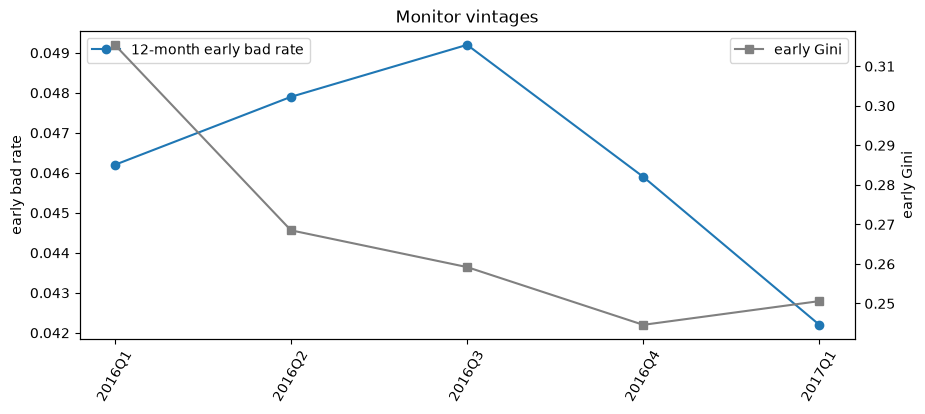

In [6]:
# Evidence — the early indicator by quarter (the only performance signal for censored vintages)
perf = summary["performance"]
fig, ax1 = plt.subplots(figsize=(10, 4)); ax1.plot(perf.vintage_quarter, perf.early_bad_rate, marker="o", label="12-month early bad rate")
ax1.set_ylabel("early bad rate"); ax1.tick_params(axis="x", rotation=60); ax2 = ax1.twinx(); ax2.plot(perf.vintage_quarter, perf.early_gini, marker="s", color="grey", label="early Gini"); ax2.set_ylabel("early Gini")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right"); plt.title("Monitor vintages"); plt.show()

### Decision U — Scenarios

Three simulated drifts on the OOT year: a covariate shift (P(X) moves, P(Y|X) does not), a concept shift (the bad rate rises, ordering intact) and an ordering decay (outcomes shuffled). For each, which rung should the rule land on, and does it?

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**All three scenarios now land on the right action.** Each is a single period, so the rule treats a breach as if it persisted.

| Scenario | Action | Observed Gini [95% CI] | Expected Gini | Other evidence |
|---|---|---|---|---|
| Covariate shift | investigate population (no model change) | 0.2613 [0.2546, 0.2679] | 0.2584 (gap −0.0028) | PSI 0.1066; max CSI 0.4084; slope 1.007; shift 0.086 |
| Concept shift (bad rate ×1.5, ordering kept) | recalibrate | 0.2889 [0.2846, 0.2932] | 0.2788 (gap −0.0101) | shift 0.501; slope 1.036 |
| Ordering decay (30% of outcomes shuffled) | re-estimate | 0.2009 [0.1957, 0.2060] | 0.2788 (gap 0.0779, half width 0.0052) | slope 0.695 |

- **Covariate shift.** Half of the 2016 loans are drawn without replacement, tilted towards higher `new_trades_share_24m` and `num_tl_op_past_12m` (realised shift 0.40 and 0.39 sd); each loan keeps its outcome. Gini falls 0.0226 below the reference, but the card expects that fall on this narrower population (observed 0.2613, expected 0.2584). Calibration holds. So it is a population shift: investigate, no model change. Before the expected-Gini check this scenario went to "redevelop".
- **Concept shift.** Ranking holds (Gini at the reference), the level moves (shift 0.501): recalibrate.
- **Ordering decay.** Gini 0.2009 is far below both the reference and the expected 0.2788: re-estimate. CSI is 0.0827, so not redevelop.

In [7]:
scenarios = {
    "covariate shift (half the loans drawn, tilted towards two attributes)": M.simulate_drift(oot, "covariate", attributes=card.attributes[:2], strength=0.5),
    "concept shift (bad rate x1.5, ordering kept)": M.simulate_drift(oot, "concept", strength=0.5, risk_col="eta"),
    "ordering decay (30% outcomes shuffled)": M.simulate_drift(oot, "ordering", strength=0.3),
}
rows = []
for name, d in scenarios.items():
    sc = S.score(d, card, specs); d["score"] = sc["score"].values; d["eta"] = sc["eta"].values + CARD_SHIFT   # deployed card
    obs = d[d.bad.notna()]
    p = V.psi(tr["score"], d["score"])["psi"]; g = V.delong_ci(obs["bad"].to_numpy(dtype=int), obs["score"]); c = V.calibration_slope_intercept(obs["bad"], obs["eta"])
    mx = max(B.csi(specs[a], d[a])[0] for a in card.attributes)
    x = M.expected_gini(1 / (1 + np.exp(-obs["eta"].to_numpy(dtype=float))), obs["score"], gini_se=g["gini_se"])
    rows.append({"scenario": name, **M.decide_action(p, g_dev["gini"], g["gini"], g["gini_ci"], c["slope"], mx, slope_band=SLOPE_BAND,
                                                     calib_intercept_shift=c["intercept_only_shift"], expected_gini_ci=x["expected_ci"])})
SCEN = pd.DataFrame(rows); display(SCEN)
print("covariate shift: realised mean shift in sd", M.realised_shift(oot, scenarios[list(scenarios)[0]], card.attributes[:2]),
      "· n", len(scenarios[list(scenarios)[0]]))

,scenario,action,gini_now,gini_ci_low,gini_ci_high,gini_drop,expected_gini,gap_to_expected,half_width,below_reference,versus_expected,breach,persistent_breach,calibration_off,psi,max_csi,calib_slope,calib_intercept_shift
0,"covariate shift (half the loans drawn, tilted ...",investigate population (no model change),0.2613,0.2546,0.2679,0.0226,0.2584,-0.0028,0.0066,True,at or above expected,False,False,False,0.1066,0.4084,1.007,0.086
1,"concept shift (bad rate x1.5, ordering kept)",recalibrate,0.2889,0.2846,0.2932,-0.0051,0.2788,-0.0101,0.0043,False,at or above expected,False,False,True,0.0009,0.0827,1.036,0.501
2,ordering decay (30% outcomes shuffled),re-estimate,0.2009,0.1957,0.2060,0.0829,0.2788,0.0779,0.0052,True,below expected,True,True,True,0.0009,0.0827,0.695,0.064


covariate shift: realised mean shift in sd {'new_trades_share_24m': 0.403, 'num_tl_op_past_12m': 0.391} · n 212809


### Decision V — The monitoring plan

Write the plan: metrics, cadence, thresholds, owner, and the action per trigger. This becomes section 8 of `docs/model_document.md`.

**Your plan:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Monitoring plan (draft for section 8 of `docs/model_document.md`). It monitors the deployed card (intercept recalibrated on 2015).**

| Metric | Cadence | Threshold | Action |
|---|---|---|---|
| Score PSI against development | monthly | 0.10 watch, 0.25 act; chi-square as a detector only | investigate population (no model change) |
| CSI per card attribute | quarterly | 0.10 watch, 0.25 act | review that attribute's bins; `percent_bc_gt_75` is on watch (0.1053) |
| Early indicator (12-month bad rate and Gini) | quarterly | early Gini outside the quarter's own interval | bring the annual review forward |
| Gini against reference and expected | quarterly, once 24-month outcomes exist | reference above the quarter's own interval | below expected by more than half the interval width: watch on the first breach, re-estimate on the second consecutive one (redevelop if a card attribute's CSI is above 0.25); by less: watch; at or above expected: investigate population |
| Calibration level | quarterly | intercept-only shift beyond ±0.15 log-odds | recalibrate the intercept |
| Calibration slope | quarterly | outside 0.9–1.1 | recalibrate (slope and intercept) |
| Full assessment | annual | all of the above plus segment Gini (term, file depth, purpose) | model-risk sign-off |

**Owner:** model owner (to be named), with independent validation reviewing the annual assessment.

**Standing findings:**
- Deployment: the card goes live with its intercept recalibrated on 2015 (+0.198 log-odds), which brings 2016 to a calibration-in-the-large shift of 0.064.
- Ranking decay is persistent from 2016Q3: first breach in 2016Q3 (watch), second in 2016Q4 (re-estimate, 0.2575 against an expected 0.2753), and again in 2017Q1. The card should be re-estimated.
- Calibration of the deployed card is within bounds in every quarter.